# 07 My own wafers: a generator as an extra test

**What this notebook does.** I draw wafer maps myself, by rules, for the same 38 types the dataset has, and test
the trained model on them. A Center is "fail the dies close to the middle", a Scratch is "fail the dies along a
thin line", and so on.

**Why.** The test part comes from the same source as the training part. Wafers from a different source are a
harder test: does the model know what a Center is, or only what MixedWM38's Centers look like? QC-05 asks that
recall on my wafers is at most 15 points lower than on the real test part.

**Only for testing.** I never train on these. If my rules are a bit off, that mistake could end up inside the
model. And because my wafers might not look like the real ones, I compare them with the
real ones on numbers first, not on looks.

**In:** `output/split.npz`, `output/forest.joblib`, `output/test_scores.csv` **Out:** `output/generated.npz`, `output/generated_scores.csv`

## 1. Load what I need

**Why this step:** I need the real training wafers to measure the patterns, the model to test, and the real test scores to compare with.

**The problem:** Load the split, the forest, and only the training part of the maps.

**How:** Only training wafers, so the rules are based on data a model is allowed to learn from.

In [1]:
import csv
import json
import os

import numpy as np
import matplotlib.pyplot as plt
import joblib

import wafer

split = np.load("output/split.npz")
maps = split["maps"]
labels = split["labels"]
train_maps = maps[split["train_idx"]]
train_labels = labels[split["train_idx"]]

forest = joblib.load("output/forest.joblib")
print("Real training wafers:", len(train_maps))

Real training wafers: 25822


**What you should see:** The number of real training wafers.

## 2. The round shape of a wafer

**Why this step:** My wafers need the same round shape as real ones. Otherwise the rings and slices measure a different area, and the comparison is off before I draw anything.

**The problem:** Find the real outline: which squares hold a die.

**How:** `(train_maps > 0)` is True wherever a square holds a die. `.mean(axis=0)` gives per square the share of wafers with a die there. Above 0.5 means it's part of the wafer.\
`EDGE` is the distance of the outermost die to the middle, so rules like "near the edge" know where the edge is.

Dies on a wafer: 2061
The outermost die is 25.6 squares from the middle


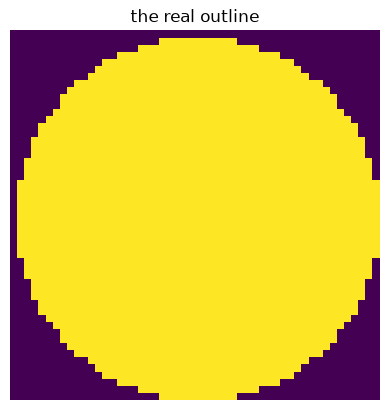

In [2]:
OUTLINE = (train_maps > 0).mean(axis=0) > 0.5

# How far out the dies go, measured from the middle like in wafer.py
EDGE = wafer.DISTANCE[OUTLINE].max()

print("Dies on a wafer:", OUTLINE.sum())
print(f"The outermost die is {EDGE:.1f} squares from the middle")

plt.imshow(OUTLINE)
plt.title("the real outline")
plt.axis("off")
plt.show()

**What you should see:** How many dies a wafer holds, how far the outermost die is from the middle, and a picture
of the circle.

## 3. Measure the real patterns first

**Why this step:** My rules need a target. If I write "a Center is a blob in the middle" without measuring, I'm guessing how big and how failed that blob is.

**The problem:** For every basic defect, average four numbers over the real wafers with only that defect.

**How:** The four numbers: share failed on the whole wafer, ring 0 (the middle), ring 4 (the edge), and the highest of the 8 slices. The highest slice doesn't care which side a pattern sits on, only how much it sits on one side. That matters, because my generator puts patterns at random angles.\
`describe()` and `wafers_with_only()` are two small helper functions: the first averages those four numbers for a set of wafers, the second finds wafers with exactly one defect.

In [3]:
def describe(some_maps):
    # Average share failed, ring 0, ring 4 and highest slice over a set of wafers
    table = wafer.feature_table(some_maps)
    highest_slice = table[:, 6:14].max(axis=1)
    return [table[:, 0].mean(), table[:, 1].mean(), table[:, 5].mean(), highest_slice.mean()]


def wafers_with_only(defect_name, which_labels):
    # Positions of the wafers that have this one defect and nothing else
    wanted = np.zeros(8, dtype=which_labels.dtype)
    wanted[wafer.DEFECTS.index(defect_name)] = 1
    return np.where((which_labels == wanted).all(axis=1))[0]


real = {}
normal = np.where(train_labels.sum(axis=1) == 0)[0]
real["Normal"] = describe(train_maps[normal])
for defect in wafer.DEFECTS:
    real[defect] = describe(train_maps[wafers_with_only(defect, train_labels)])

print("Real wafers: share failed, ring 0, ring 4, highest slice")
for name in real:
    print(name, np.round(real[name], 2))

Real wafers: share failed, ring 0, ring 4, highest slice
Normal [0.08 0.08 0.08 0.1 ]
Center [0.24 0.68 0.19 0.3 ]
Donut [0.29 0.41 0.19 0.35]
Edge-Loc [0.24 0.2  0.35 0.31]
Edge-Ring [0.29 0.19 0.5  0.33]
Loc [0.24 0.2  0.24 0.46]
Near-Full [0.83 0.9  0.74 0.93]
Scratch [0.21 0.19 0.21 0.27]
Random [0.46 0.53 0.45 0.58]


**What you should see:** The four numbers for Normal and for each basic defect. Check them against the pictures in
notebook 01: is the Center high in ring 0, the Edge-Ring in ring 4, the Loc high on one slice? These are the
targets for my rules.

## 4. Measure the background

**Why this step:** No real wafer is perfectly clean, there are always failed dies scattered around. My wafers need the same background, or the model could tell them apart from real ones by that alone.

**The problem:** Measure how many dies fail outside the pattern.

**How:** For a Normal wafer that's simply its share failed. For a wafer with a defect I take the ring where the pattern is *not*: the lowest of its 5 rings is the part the defect doesn't touch, so that's the background. Near-Full and Random cover the whole wafer, so they're left out.

In [4]:
NOISE = real["Normal"][0]

backgrounds = []
for defect in ["Center", "Donut", "Edge-Loc", "Edge-Ring", "Loc", "Scratch"]:
    table = wafer.feature_table(train_maps[wafers_with_only(defect, train_labels)])
    lowest_ring = table[:, 1:6].min(axis=1)
    backgrounds.append(lowest_ring.mean())
DEFECT_NOISE = np.mean(backgrounds)

print(f"Background on a Normal wafer: {NOISE * 100:.1f}%")
print(f"Background on a wafer with a defect: {DEFECT_NOISE * 100:.1f}%")

Background on a Normal wafer: 7.9%
Background on a wafer with a defect: 17.0%


**What you should see:** The background on Normal wafers and on wafers with a defect. If the two differ, that's a
property of the dataset, and a model could partly tell "defect" from "Normal" by the background alone.

## 5. The rules, one pattern at a time

**Why this step:** This is the generator itself. Each rule turns some good dies into failed ones in the shape of one pattern.

**The problem:** Write one drawing function per defect, with random sizes within a range.

**How:** Every rule picks its sizes at random within a range, because real defects aren't all the same size. `rng.uniform(4, 10)` picks a random decimal between 4 and 10, `rng.integers(15, 40)` a whole number.\
`fail_where(w, area, share, rng)` fails each die inside an area with chance `share`: `rng.random((52, 52)) < share` is True on about that share of the squares.\
For Edge-Loc, `(wafer.ANGLE - start) % 360 < width` is True inside a slice of the wafer that starts at angle `start` and is `width` degrees wide. `% 360` is the rest after dividing by 360, so a slice that crosses the point where -180 jumps to 180 still works.\
The scratch walks a straight line one step at a time: `np.sin` and `np.cos` turn a direction into how far down and how far across each step goes.\
Every rule returns the settings it used, so a strange wafer can be traced back (FR-09).

In [5]:
def fail_where(w, area, share, rng):
    # Inside the area, turn each die into a failed die with chance `share`
    chance = rng.random((52, 52)) < share
    w[area & OUTLINE & chance] = 2


def distance_from(row, col):
    return np.sqrt((wafer.ROWS - row) ** 2 + (wafer.COLS - col) ** 2)


def draw_center(w, rng):
    radius = rng.uniform(4, 10)
    row = 25.5 + rng.uniform(-3, 3)     # a little off the exact middle
    col = 25.5 + rng.uniform(-3, 3)
    share = rng.uniform(0.7, 1.0)
    fail_where(w, distance_from(row, col) <= radius, share, rng)
    return {"radius": radius, "row": row, "col": col, "share": share}


def draw_donut(w, rng):
    inner = rng.uniform(2, 6)
    width = rng.uniform(4, 8)
    share = rng.uniform(0.6, 0.95)
    band = (wafer.DISTANCE >= inner) & (wafer.DISTANCE <= inner + width)
    fail_where(w, band, share, rng)
    return {"inner": inner, "width": width, "share": share}


def draw_edge_loc(w, rng):
    depth = rng.uniform(3, 8)           # how far into the wafer it goes
    start = rng.uniform(-180, 180)      # where around the wafer it starts
    width = rng.uniform(30, 100)        # how many degrees it covers
    share = rng.uniform(0.6, 0.95)
    around = (wafer.ANGLE - start) % 360 < width
    near_edge = wafer.DISTANCE > EDGE - depth
    fail_where(w, near_edge & around, share, rng)
    return {"depth": depth, "start": start, "width": width, "share": share}


def draw_edge_ring(w, rng):
    thickness = rng.uniform(1.5, 4)
    share = rng.uniform(0.6, 0.95)
    fail_where(w, wafer.DISTANCE > EDGE - thickness, share, rng)
    return {"thickness": thickness, "share": share}


def draw_loc(w, rng):
    # A blob somewhere, but away from the edge, otherwise it's an Edge-Loc
    from_middle = rng.uniform(4, EDGE - 8)
    angle = rng.uniform(0, 2 * np.pi)
    row = 25.5 + from_middle * np.sin(angle)
    col = 25.5 + from_middle * np.cos(angle)
    radius = rng.uniform(4, 8)
    share = rng.uniform(0.7, 1.0)
    fail_where(w, distance_from(row, col) <= radius, share, rng)
    return {"from_middle": from_middle, "radius": radius, "share": share}


def draw_near_full(w, rng):
    share = rng.uniform(0.75, 0.95)
    fail_where(w, OUTLINE, share, rng)
    return {"share": share}


def draw_scratch(w, rng):
    from_middle = rng.uniform(0, 15)
    angle = rng.uniform(0, 2 * np.pi)
    row = 25.5 + from_middle * np.sin(angle)
    col = 25.5 + from_middle * np.cos(angle)
    direction = rng.uniform(0, 2 * np.pi)
    length = rng.integers(15, 40)

    # Walk the line one step at a time, fail every die it crosses
    for step_number in range(length):
        r = int(round(row + step_number * np.sin(direction)))
        c = int(round(col + step_number * np.cos(direction)))
        if 0 <= r < 52 and 0 <= c < 52 and OUTLINE[r, c]:
            w[r, c] = 2
    return {"from_middle": from_middle, "direction": direction, "length": length}


def draw_random(w, rng):
    share = rng.uniform(0.3, 0.55)
    fail_where(w, OUTLINE, share, rng)
    return {"share": share}


# One rule per position of the label
DRAW = {
    "Center": draw_center,
    "Donut": draw_donut,
    "Edge-Loc": draw_edge_loc,
    "Edge-Ring": draw_edge_ring,
    "Loc": draw_loc,
    "Near-Full": draw_near_full,
    "Scratch": draw_scratch,
    "Random": draw_random,
}
print("Rules for:", list(DRAW))

Rules for: ['Center', 'Donut', 'Edge-Loc', 'Edge-Ring', 'Loc', 'Near-Full', 'Scratch', 'Random']


**What you should see:** A list of the 8 defects that have a rule. Note: the Scratch rule draws a line one die
wide.

## 6. Make one wafer, and look at it

**Why this step:** Before making 1,900 wafers, one should look right.

**The problem:** Combine the rules: a clean wafer, background noise, then every defect on the label.

**How:** `make_wafer(label, rng)` starts from the outline full of good dies (`np.where(OUTLINE, 1, 0)`), adds the background noise from step 4, then calls the rule for every defect that has a 1 in the label. It also collects the settings every rule used.

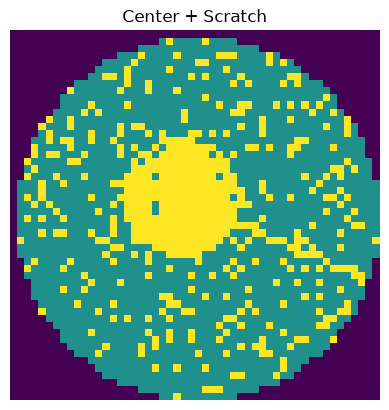

{'noise': 0.17, 'Center': {'radius': 8.45, 'row': 22.99, 'col': 23.77, 'share': 0.92}, 'Scratch': {'from_middle': 1.47, 'direction': 0.41, 'length': 36.0}}


In [6]:
def make_wafer(label, rng):
    # A clean wafer: good dies inside the outline, empty outside
    w = np.where(OUTLINE, 1, 0).astype(np.int8)

    # The background noise, at the level measured in step 4
    if label.sum() == 0:
        noise = NOISE
    else:
        noise = DEFECT_NOISE
    fail_where(w, OUTLINE, noise, rng)

    settings = {"noise": round(float(noise), 3)}
    for i in range(8):
        if label[i] == 1:
            used = DRAW[wafer.DEFECTS[i]](w, rng)
            rounded = {}
            for key in used:
                rounded[key] = round(float(used[key]), 2)
            settings[wafer.DEFECTS[i]] = rounded
    return w, settings


rng = np.random.default_rng(7)
test_label = np.array([1, 0, 0, 0, 0, 0, 1, 0])   # Center + Scratch
w, s = make_wafer(test_label, rng)

plt.imshow(w)
plt.title(wafer.label_name(test_label))
plt.axis("off")
plt.show()
print(s)

**What you should see:** A round wafer with a yellow blob in the middle and a thin yellow line, plus the settings that made it.

## 7. Make a set for all 38 types

**Why this step:** One wafer proves the rules work, a full set lets me test the model.

**The problem:** 50 wafers for every type that's in MixedWM38, 1,900 in total.

**How:** Only the label combinations that are in the dataset itself, so I invent no new types (FR-12 is a Won't). A seed again, `default_rng(2026)`, so the set is the same every run. `json.dumps(settings)` turns the settings into one line of text, so they can be saved next to the maps.

In [7]:
PER_TYPE = 50
rng = np.random.default_rng(2026)

types = np.unique(labels, axis=0)

gen_maps = []
gen_labels = []
gen_settings = []
for label in types:
    for n in range(PER_TYPE):
        w, s = make_wafer(label, rng)
        gen_maps.append(w)
        gen_labels.append(label)
        gen_settings.append(json.dumps(s))

gen_maps = np.array(gen_maps)
gen_labels = np.array(gen_labels)

print("Generated:", gen_maps.shape, "for", len(types), "types")
print("Values in them:", np.unique(gen_maps))

Generated: (1900, 52, 52) for 38 types
Values in them: [0 1 2]


**What you should see:** The shape of the set, 50 wafers for every type, with only the values 0, 1 and 2.

## 8. Do they match the real ones, in numbers?

**Why this step:** This is the check instead of "it looks real to me". A rule that is far off makes its test score mean nothing.

**The problem:** The same four numbers as step 3, mine next to the real ones, with a warning when they differ more than 0.15.

**How:** I loop over the defects, describe my wafers of that type, and compare each of the four numbers with the real one.

In [8]:
print("real vs mine: share failed, ring 0, ring 4, highest slice")
for defect in wafer.DEFECTS:
    mine = describe(gen_maps[wafers_with_only(defect, gen_labels)])
    print(defect)
    print("  real:", np.round(real[defect], 2))
    print("  mine:", np.round(mine, 2))
    for k in range(4):
        if abs(real[defect][k] - mine[k]) > 0.15:
            print("  more than 0.15 off: change this rule in step 5")
            break

real vs mine: share failed, ring 0, ring 4, highest slice
Center
  real: [0.24 0.68 0.19 0.3 ]
  mine: [0.23 0.78 0.17 0.29]
Donut
  real: [0.29 0.41 0.19 0.35]
  mine: [0.25 0.47 0.17 0.28]
Edge-Loc
  real: [0.24 0.2  0.35 0.31]
  mine: [0.21 0.17 0.28 0.37]
Edge-Ring
  real: [0.29 0.19 0.5  0.33]
  mine: [0.32 0.17 0.63 0.35]
Loc
  real: [0.24 0.2  0.24 0.46]
  mine: [0.21 0.31 0.17 0.35]
Near-Full
  real: [0.83 0.9  0.74 0.93]
  mine: [0.87 0.86 0.87 0.89]
Scratch
  real: [0.21 0.19 0.21 0.27]
  mine: [0.18 0.2  0.18 0.22]
Random
  real: [0.46 0.53 0.45 0.58]
  mine: [0.53 0.53 0.53 0.57]


**What you should see:** Per defect the four numbers, real next to mine, and a warning where a rule is more than
0.15 off. Four numbers can't describe a shape, so a rule that passes here can still look different.

## 9. Side by side

**Why this step:** Numbers first, then the eyes. The generator is easier to judge from a picture.

**The problem:** Draw one real wafer and one of mine for every basic defect.

**How:** Top row real, bottom row mine. `plt.subplot(2, 8, i + 9)` puts mine in the second row.

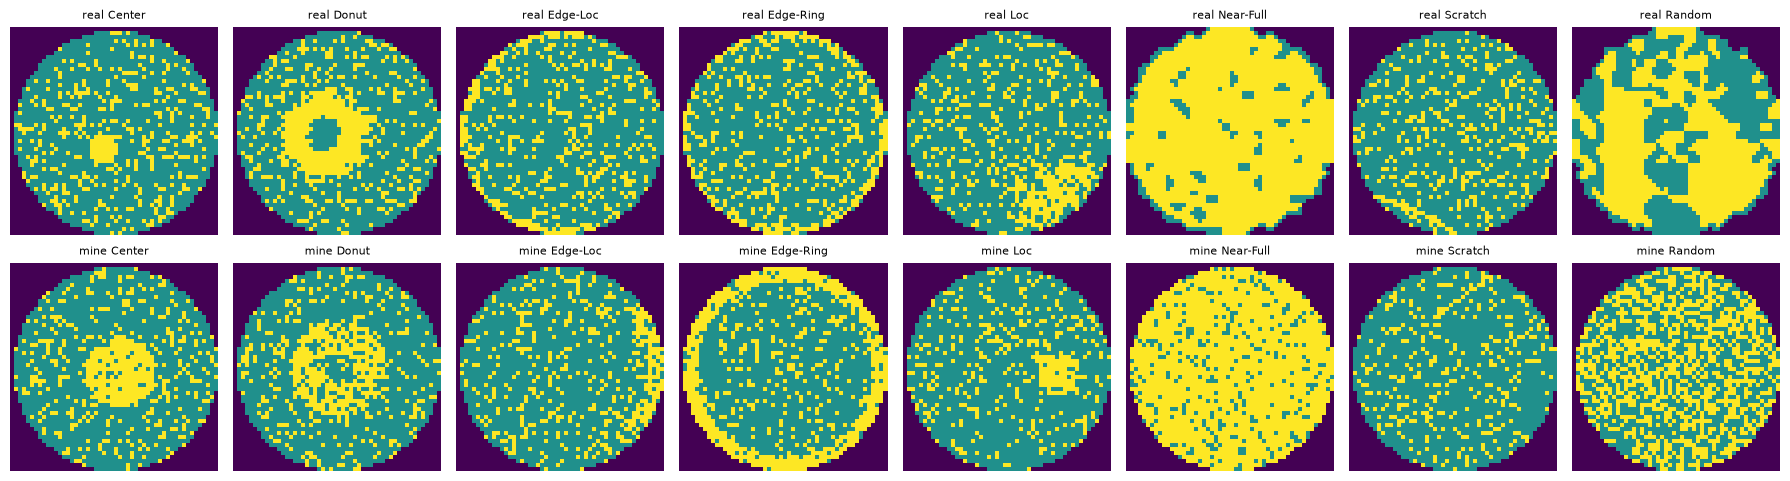

In [9]:
plt.figure(figsize=(18, 5))

for i in range(8):
    defect = wafer.DEFECTS[i]
    plt.subplot(2, 8, i + 1)
    plt.imshow(train_maps[wafers_with_only(defect, train_labels)[0]])
    plt.title(f"real {defect}", fontsize=8)
    plt.axis("off")

    plt.subplot(2, 8, i + 9)
    plt.imshow(gen_maps[wafers_with_only(defect, gen_labels)[0]])
    plt.title(f"mine {defect}", fontsize=8)
    plt.axis("off")

plt.tight_layout()
plt.show()

**What you should see:** 16 wafers, real on top, mine below. Compare the shapes, not only the amount of yellow.

## 10. Test the model on my wafers (QC-05)

**Why this step:** This is the actual question: does the model work on wafers from a different source?

**The problem:** Score the unchanged forest on my 1,900 wafers, and compare recall per defect with the real test part.

**How:** Same features, same forest, nothing retrained. The real test recall comes from `output/test_scores.csv`, which notebook 06 saved. `csv.DictReader` reads it row by row as name to value.\
The gap is real recall minus mine, in percentage points. QC-05 allows at most 15.

In [10]:
gen_pred = forest.predict(wafer.feature_table(gen_maps))
gen_recall, gen_precision = wafer.scores_per_defect(gen_labels, gen_pred)

real_recall = {}
with open("output/test_scores.csv", encoding="utf-8") as file:
    for row in csv.DictReader(file):
        real_recall[row["defect"]] = float(row["recall"])

gaps = []
for i in range(8):
    defect = wafer.DEFECTS[i]
    gap = (real_recall[defect] - gen_recall[i]) * 100
    gaps.append(gap)
    print(f"{defect}: real test {real_recall[defect] * 100:.1f}%, my wafers {gen_recall[i] * 100:.1f}%, gap {gap:.1f}")

print()
print(f"All 8 right on my wafers: {wafer.share_all_eight_right(gen_labels, gen_pred) * 100:.1f}%")
print(f"Biggest gap: {max(gaps):.1f} points (QC-05 allows 15)")

Center: real test 94.5%, my wafers 79.7%, gap 14.8
Donut: real test 93.8%, my wafers 89.7%, gap 4.2
Edge-Loc: real test 84.4%, my wafers 75.5%, gap 8.9
Edge-Ring: real test 95.3%, my wafers 92.0%, gap 3.3
Loc: real test 87.5%, my wafers 31.6%, gap 56.0
Near-Full: real test 100.0%, my wafers 100.0%, gap 0.0
Scratch: real test 86.0%, my wafers 14.6%, gap 71.4
Random: real test 71.0%, my wafers 100.0%, gap -28.9

All 8 right on my wafers: 28.9%
Biggest gap: 71.4 points (QC-05 allows 15)


**What you should see:** Recall per defect on the real test part and on my wafers, the gap, all 8 right on my
wafers, and the biggest gap next to QC-05's 15 points. Where a gap is big, ask why: is my rule off, or does the
model use something in the real wafers that my wafers don't have?

## 11. Save the set and the scores

**Why this step:** FR-09 asks that every map is saved with its label and the settings it was made with. Notebook 08 checks that.

**The problem:** Save my wafers, their labels and settings, and the comparison.

**How:** Same `np.savez_compressed` and `csv.writer` as before.

In [11]:
np.savez_compressed("output/generated.npz",
                    maps=gen_maps, labels=gen_labels, settings=np.array(gen_settings))

with open("output/generated_scores.csv", "w", newline="", encoding="utf-8") as file:
    writer = csv.writer(file)
    writer.writerow(["defect", "recall_real_test", "recall_my_wafers", "gap_points"])
    for i in range(8):
        writer.writerow([wafer.DEFECTS[i], round(real_recall[wafer.DEFECTS[i]], 4), round(gen_recall[i], 4),
                         round(gaps[i], 1)])

print("Saved output/generated.npz and output/generated_scores.csv")

Saved output/generated.npz and output/generated_scores.csv


**What you should see:** One "Saved" line.

## What this means

The output of step 10 shows per defect where the model works on my wafers and where it doesn't. Matching on four
numbers is not enough to prove a rule looks real. What to change next depends on why the big gaps happen.

## Functions in this notebook

| Function | What it does | Where to read more |
|---|---|---|
| `rng.uniform / rng.integers` | a random decimal / whole number in a range | [docs](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.uniform.html) |
| `rng.random` | random numbers between 0 and 1 | [docs](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.random.html) |
| `np.sin / np.cos` | turn an angle into down and across | [docs](https://numpy.org/doc/stable/reference/generated/numpy.sin.html) |
| `np.where(OUTLINE, 1, 0)` | 1 where the outline is True, 0 elsewhere | [docs](https://numpy.org/doc/stable/reference/generated/numpy.where.html) |
| `json.dumps` | turns a dictionary into one line of text | [docs](https://docs.python.org/3/library/json.html) |
| `csv.DictReader` | reads a .csv row by row as name to value | [docs](https://docs.python.org/3/library/csv.html#csv.DictReader) |